# 고변동성 구간의 낙폭과대주 전략 (이격도 리버전 × VKOSPI 필터)

증권사 퀀트 보고서에서 본 아이디어를 직접 백테스트해 본 노트북이다.

> 시장 변동성이 커진 구간에서는 기존 주도주보다 최근 많이 빠진 종목이 더 강하게 반등한다.

보고서는 1개월 이격도가 낮은 종목을 사는 팩터가 VKOSPI 18p 이상 구간에서 월평균 1.2%(연환산 14.8%) 수준의 성과를 냈다고 정리했다. 여기서는 그 주장을 KOSPI200 종목으로 단순하게 옮겨서, **VKOSPI 필터가 실제로 의미가 있는지**를 확인하는 데 초점을 뒀다.

## 전략 규칙

| 항목 | 내용 |
|---|---|
| 유니버스 | KOSPI200 구성종목 200개 (현재 시점 기준 리스트) |
| 시그널 | 1개월 이격도 = 종가 / 20일 이동평균 × 100 |
| 종목 선정 | 매월 마지막 거래일에 이격도 하위 20개 |
| 진입 조건 | 그날 VKOSPI 종가가 18 이상일 때만 진입, 아니면 현금 |
| 체결 | 다음 거래일 시가 매수 → 다음 월말 신호일의 다음 거래일 시가 매도 |
| 비중 | 동일가중 |
| 기간 | 2021-01 ~ 2026-06 |

이격도가 90이면 최근 한 달 평균보다 10% 낮은 가격에 거래되고 있다는 뜻이다. 값이 낮을수록 낙폭과대로 본다.

## 왜 될 것 같은가

변동성이 튀는 시점은 대체로 지수가 급하게 빠진 직후다. 이때는 종목별 펀더멘털보다 수급(손절, 마진콜, 패시브 매도) 때문에 같이 끌려 내려간 종목이 많고, 그런 종목일수록 지수가 진정될 때 되돌림도 크다. 반대로 변동성이 낮은 구간에서 혼자 빠진 종목은 개별 악재일 가능성이 높아서 단순히 싸졌다는 이유로 사면 물리기 쉽다.

그래서 확인하려는 건 세 가지다.

1. VKOSPI 필터를 건 전략이 필터 없는 전략보다 위험 대비 성과가 좋은가
2. 그 차이가 낙폭과대주를 골라서 생긴 것인가, 아니면 변동성이 높은 달 다음에 시장 전체가 올라서 생긴 것인가
3. 임계값 18과 분석 기간을 바꿔도 결론이 유지되는가

## 먼저 알아둘 한계

결과 수치를 보기 전에 짚어둔다. 자세한 내용은 맨 아래에 다시 정리했다.

- 유니버스가 **현재** KOSPI200 구성종목이다. 과거 시점의 실제 구성종목이 아니라서 생존편향이 들어간다. 빠졌다가 결국 살아남아 지수에 남은 종목만 사는 셈이라 수익률이 실제보다 좋게 나온다.
- 기본 결과는 거래비용을 뺀 수치다. 비용을 넣은 버전은 따로 계산했다.
- 표본이 5년 남짓(월 60여 개)이라 통계적으로 강한 결론을 내리기는 어렵다.

## 0. 환경 설정

In [1]:
# Colab 기준. 로컬이면 requirements는 finance-datareader, tqdm, openpyxl, scipy, matplotlib
%pip install -q finance-datareader tqdm openpyxl

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import FinanceDataReader as fdr
from scipy import stats
from tqdm import tqdm

In [3]:
# 파라미터는 여기서만 바꾼다
START = "2021-01-01"
END = "2026-06-30"
BACKTEST_START = "2021-02-01"   # 20일 이동평균이 쌓이는 첫 달은 건너뛰고 2월 신호일부터 시작

MA_WINDOW = 20           # 1개월 이동평균 (거래일)
TOP_N = 20               # 이격도 하위 몇 종목을 살지
VKOSPI_THRESHOLD = 18    # 이 값 이상일 때만 진입
COST_BPS = 20            # 비용 반영 버전에서 쓰는 편도 비용 (bp, 세금+수수료+슬리피지 대략)

PRICE_CACHE = "kospi200_fdr_ohlcv.csv"   # 한 번 받은 시세는 여기 저장해 두고 재사용
VKOSPI_PATH = "vkospi.xlsx"              # KRX 정보데이터시스템에서 받은 VKOSPI 일별 시세

## 1. 데이터

### 1-1. 종목 시세

KOSPI200 구성종목 리스트를 직접 정리해서 넣었다. 시세는 FinanceDataReader로 받는다(수정주가 기준, 배당은 반영되지 않는다).

200종목을 받는 데 4~5분 걸려서, 한 번 받으면 CSV로 저장하고 다음부터는 그 파일을 읽도록 했다. 새로 받고 싶으면 CSV를 지우면 된다.

In [4]:
STOCKS = {
    "005930": "삼성전자",
    "000660": "SK하이닉스",
    "402340": "SK스퀘어",
    "009150": "삼성전기",
    "005380": "현대차",
    "032830": "삼성생명",
    "028260": "삼성물산",
    "373220": "LG에너지솔루션",
    "207940": "삼성바이오로직스",
    "034730": "SK",
    "329180": "HD현대중공업",
    "034020": "두산에너빌리티",
    "012450": "한화에어로스페이스",
    "000270": "기아",
    "105560": "KB금융",
    "012330": "현대모비스",
    "055550": "신한지주",
    "006400": "삼성SDI",
    "068270": "셀트리온",
    "267260": "HD현대일렉트릭",
    "066570": "LG전자",
    "010120": "LS ELECTRIC",
    "042660": "한화오션",
    "035420": "NAVER",
    "086790": "하나금융지주",
    "298040": "효성중공업",
    "000810": "삼성화재",
    "042700": "한미반도체",
    "009540": "HD한국조선해양",
    "005490": "POSCO홀딩스",
    "015760": "한국전력",
    "000150": "두산",
    "006800": "미래에셋증권",
    "010130": "고려아연",
    "011070": "LG이노텍",
    "316140": "우리금융지주",
    "010140": "삼성중공업",
    "051910": "LG화학",
    "064350": "현대로템",
    "017670": "SK텔레콤",
    "033780": "KT&G",
    "011200": "HMM",
    "138040": "메리츠금융지주",
    "079550": "LIG넥스원",
    "267250": "HD현대",
    "096770": "SK이노베이션",
    "024110": "기업은행",
    "035720": "카카오",
    "003670": "포스코퓨처엠",
    "003550": "LG",
    "307950": "현대오토에버",
    "272210": "한화시스템",
    "018260": "삼성에스디에스",
    "278470": "에이피알",
    "086280": "현대글로비스",
    "047810": "한국항공우주",
    "030200": "KT",
    "000720": "현대건설",
    "071050": "한국금융지주",
    "006260": "LS",
    "010950": "S-Oil",
    "003490": "대한항공",
    "005940": "NH투자증권",
    "443060": "HD현대마린솔루션",
    "016360": "삼성증권",
    "323410": "카카오뱅크",
    "259960": "크래프톤",
    "005830": "DB손해보험",
    "039490": "키움증권",
    "003230": "삼양식품",
    "047050": "포스코인터내셔널",
    "028050": "삼성E&A",
    "047040": "대우건설",
    "352820": "하이브",
    "180640": "한진칼",
    "007660": "이수페타시스",
    "064400": "LG씨엔에스",
    "000880": "한화",
    "161390": "한국타이어앤테크놀로지",
    "062040": "산일전기",
    "004170": "신세계",
    "326030": "SK바이오팜",
    "000990": "DB하이텍",
    "001440": "대한전선",
    "021240": "코웨이",
    "034220": "LG디스플레이",
    "454910": "두산로보틱스",
    "078930": "GS",
    "032640": "LG유플러스",
    "241560": "두산밥캣",
    "090430": "아모레퍼시픽",
    "009830": "한화솔루션",
    "000100": "유한양행",
    "377300": "카카오페이",
    "267270": "HD건설기계",
    "011790": "SKC",
    "029780": "삼성카드",
    "138930": "BNK금융지주",
    "036570": "엔씨소프트",
    "128940": "한미약품",
    "271560": "오리온",
    "023530": "롯데쇼핑",
    "001040": "CJ",
    "002380": "KCC",
    "175330": "JB금융지주",
    "066970": "엘앤에프",
    "069960": "현대백화점",
    "082740": "한화엔진",
    "052690": "한전기술",
    "088350": "한화생명",
    "010060": "OCI홀딩스",
    "018880": "한온시스템",
    "004020": "현대제철",
    "051900": "LG생활건강",
    "022100": "포스코DX",
    "111770": "영원무역",
    "450080": "에코프로머티",
    "001450": "현대해상",
    "009420": "한올바이오파마",
    "035250": "강원랜드",
    "036460": "한국가스공사",
    "251270": "넷마블",
    "011780": "금호석유화학",
    "302440": "SK바이오사이언스",
    "483650": "달바글로벌",
    "011170": "롯데케미칼",
    "383220": "F&F",
    "014680": "한솔케미칼",
    "017800": "현대엘리베이터",
    "097950": "CJ제일제당",
    "012750": "에스원",
    "005850": "에스엘",
    "139130": "iM금융지주",
    "028670": "팬오션",
    "375500": "DL이앤씨",
    "004990": "롯데지주",
    "026960": "동서",
    "204320": "HL만도",
    "139480": "이마트",
    "009970": "영원무역홀딩스",
    "000240": "한국앤컴퍼니",
    "007340": "DN오토모티브",
    "457190": "이수스페셜티케미컬",
    "081660": "미스토홀딩스",
    "030000": "제일기획",
    "161890": "한국콜마",
    "282330": "BGF리테일",
    "051600": "한전KPS",
    "071970": "HD현대마린엔진",
    "004370": "농심",
    "093370": "후성",
    "008770": "호텔신라",
    "008930": "한미사이언스",
    "007070": "GS리테일",
    "103140": "풍산",
    "120110": "코오롱인더",
    "112610": "씨에스윈드",
    "011210": "현대위아",
    "000120": "CJ대한통운",
    "192820": "코스맥스",
    "002790": "아모레퍼시픽홀딩스",
    "001800": "오리온홀딩스",
    "017960": "한국카본",
    "006280": "녹십자",
    "006040": "동원산업",
    "069620": "대웅제약",
    "073240": "금호타이어",
    "192080": "더블유게임즈",
    "361610": "SK아이이테크놀로지",
    "001430": "세아베스틸지주",
    "034230": "파라다이스",
    "298020": "효성티앤씨",
    "007310": "오뚜기",
    "004000": "롯데정밀화학",
    "000080": "하이트진로",
    "300720": "한일시멘트",
    "003090": "대웅",
    "185750": "종근당",
    "000210": "DL",
    "003240": "태광산업",
    "005300": "롯데칠성",
    "280360": "롯데웰푸드",
    "456040": "OCI",
    "071320": "지역난방공사",
    "009240": "한샘",
    "000670": "영풍",
    "298050": "HS효성첨단소재",
    "006650": "대한유화",
    "137310": "에스디바이오센서",
    "285130": "SK케미칼",
    "069260": "TKG휴켐스",
    "001680": "대상",
    "002840": "미원상사",
    "014820": "동원시스템즈",
    "268280": "미원에스씨",
    "003030": "세아제강지주",
    "005420": "코스모화학",
    "008730": "율촌화학",
    "002030": "아세아",
    "0126Z0": "삼성에피스홀딩스"
}

print(len(STOCKS), "종목")

200 종목


In [5]:
def download_prices(stocks, start, end, pause=0.1):
    # 종목별 일봉을 받아 long 형태로 합친다
    frames, failed = [], []

    for code, name in tqdm(stocks.items()):
        try:
            px = fdr.DataReader(code, start, end)
            if px.empty:
                failed.append((code, name, "empty"))
                continue
            px = px.reset_index()
            px["ticker"] = code
            px["name"] = name
            frames.append(px)
            time.sleep(pause)
        except Exception as e:
            failed.append((code, name, str(e)))

    out = pd.concat(frames, ignore_index=True).rename(columns={
        "Date": "date", "Open": "open", "High": "high", "Low": "low",
        "Close": "close", "Volume": "volume", "Change": "change",
    })
    cols = ["ticker", "name", "date", "open", "high", "low", "close", "volume", "change"]
    return out[cols], failed


if os.path.exists(PRICE_CACHE):
    # 종목코드 앞자리 0이 날아가지 않게 문자열로 읽는다
    prices = pd.read_csv(PRICE_CACHE, dtype={"ticker": str}, parse_dates=["date"])
    failed = []
    if "name" not in prices.columns:
        prices.insert(1, "name", prices["ticker"].map(STOCKS))
else:
    prices, failed = download_prices(STOCKS, START, END)
    prices.to_csv(PRICE_CACHE, index=False, encoding="utf-8-sig")

print("종목 수:", prices["ticker"].nunique())
print("전체 행 수:", len(prices))
print("기간:", prices["date"].min().date(), "~", prices["date"].max().date())
print("실패:", failed[:20])
prices.head()

종목 수: 200
전체 행 수: 259109
기간: 2021-01-04 ~ 2026-06-30
실패: []


,ticker,name,date,open,high,low,close,volume,change
0,005930,삼성전자,2021-01-04,81000,84400,80200,83000,38655276,0.024691
1,005930,삼성전자,2021-01-05,81600,83900,81600,83900,35335669,0.010843
2,005930,삼성전자,2021-01-06,83300,84500,82100,82200,42089013,-0.020262
3,005930,삼성전자,2021-01-07,82800,84200,82700,82900,32644642,0.008516
4,005930,삼성전자,2021-01-08,83300,90000,83000,88800,59013307,0.071170


### 1-2. VKOSPI

VKOSPI는 FinanceDataReader로 받을 수 없어서 KRX 정보데이터시스템에서 일별 시세를 엑셀로 내려받아 썼다. `일자`, `종가` 두 컬럼만 사용한다.

엑셀 파일 안에서 `일자`가 일부 행은 날짜 형식, 나머지는 텍스트로 섞여 들어 있어서 문자열로 통일한 뒤 날짜로 변환한다.

In [6]:
vkospi_raw = pd.read_excel(VKOSPI_PATH)

vk = (
    vkospi_raw[["일자", "종가"]]
    .rename(columns={"일자": "date", "종가": "vkospi"})
    .assign(date=lambda d: pd.to_datetime(d["date"].astype(str), format="mixed"))
    .sort_values("date")
    .reset_index(drop=True)
)

assert vk["date"].is_unique, "VKOSPI 일자가 중복됨 - 원본 파일 확인 필요"
print("기간:", vk["date"].min().date(), "~", vk["date"].max().date(), "/", len(vk), "일")
vk.tail()

기간: 2021-01-04 ~ 2026-06-30 / 1345 일


,date,vkospi
1340,2026-06-24,94.81
1341,2026-06-25,95.09
1342,2026-06-26,92.71
1343,2026-06-29,96.94
1344,2026-06-30,93.80


## 2. 이격도 계산

종목별로 20거래일 이동평균을 구하고 종가를 그 값으로 나눈다. 상장한 지 20거래일이 안 된 구간은 이동평균이 없으므로 자동으로 빠진다.

거래정지 구간에는 시가가 0으로 들어오는 경우가 있어서, 체결가로 쓰지 못하게 NaN으로 바꿔 둔다.

In [7]:
df = prices.sort_values(["ticker", "date"]).reset_index(drop=True)
df.loc[df["open"] <= 0, "open"] = np.nan

df["ma20"] = df.groupby("ticker")["close"].transform(
    lambda x: x.rolling(window=MA_WINDOW, min_periods=MA_WINDOW).mean()
)
df["disparity_1m"] = df["close"] / df["ma20"] * 100

df[["ticker", "name", "date", "close", "ma20", "disparity_1m"]].dropna().tail()

,ticker,name,date,close,ma20,disparity_1m
259104,483650,달바글로벌,2026-06-24,226000,201085.0,112.390283
259105,483650,달바글로벌,2026-06-25,232000,202335.0,114.661329
259106,483650,달바글로벌,2026-06-26,237500,204110.0,116.358826
259107,483650,달바글로벌,2026-06-29,233000,205910.0,113.156233
259108,483650,달바글로벌,2026-06-30,231500,207360.0,111.641590


## 3. 리밸런싱 테이블 만들기

매월 마지막 거래일을 신호일로 잡는다. 종가로 이격도를 계산했으니 같은 날 종가에 사는 건 현실적으로 어렵다. 그래서 **신호일 다음 거래일 시가**에 사고, **다음 신호일의 다음 거래일 시가**에 파는 것으로 계산했다.

```text
1/29 (월말, 신호)  →  2/1 시가 매수  →  2/26 (월말, 다음 신호)  →  3/2 시가 매도
```

처음에는 월말 종가 → 다음 월말 종가로 수익률을 계산했는데, 신호를 본 가격에 그대로 체결한다는 가정이라 시가 기준으로 바꿨다.

In [8]:
# 월별 마지막 거래일
month_end_dates = (
    df.groupby(df["date"].dt.to_period("M"))["date"].max().reset_index(drop=True)
)
rebal_dates = sorted(month_end_dates.unique())
next_rebal_map = {rebal_dates[i]: rebal_dates[i + 1] for i in range(len(rebal_dates) - 1)}

# 종목별 '다음 거래일'과 그날 시가
df["next_date"] = df.groupby("ticker")["date"].shift(-1)
df["next_open"] = df.groupby("ticker")["open"].shift(-1)

rebal_df = df[df["date"].isin(month_end_dates)].copy()
rebal_df = rebal_df.merge(vk, on="date", how="left")

# 매수: 신호일 다음 거래일 시가
rebal_df = rebal_df.rename(columns={"next_date": "entry_date", "next_open": "entry_open"})

# 매도: 다음 신호일의 다음 거래일 시가
rebal_df["exit_signal_date"] = rebal_df["date"].map(next_rebal_map)
exit_info = df[["ticker", "date", "next_date", "next_open"]].rename(columns={
    "date": "exit_signal_date", "next_date": "exit_date", "next_open": "exit_open",
})
rebal_df = rebal_df.merge(exit_info, on=["ticker", "exit_signal_date"], how="left")

rebal_df["fwd_ret"] = rebal_df["exit_open"] / rebal_df["entry_open"] - 1

# 이격도, VKOSPI, 체결가가 모두 있는 행만 사용 (마지막 달은 매도가가 없어서 빠진다)
rebal_df = rebal_df[rebal_df["date"] >= BACKTEST_START]
rebal_df = rebal_df.dropna(
    subset=["disparity_1m", "vkospi", "entry_open", "exit_open", "fwd_ret"]
).reset_index(drop=True)

print("신호일 수:", rebal_df["date"].nunique())
print("첫 신호일:", rebal_df["date"].min().date(), "/ 마지막 신호일:", rebal_df["date"].max().date())
print("신호일당 평균 종목 수:", round(rebal_df.groupby("date")["ticker"].count().mean(), 1))

신호일 수: 63
첫 신호일: 2021-02-26 / 마지막 신호일: 2026-04-30
신호일당 평균 종목 수: 192.2


## 4. 백테스트

함수 하나로 필터 유무를 같이 처리한다. `threshold=None`이면 매달 무조건 진입하고, 숫자를 넣으면 신호일 VKOSPI가 그 값 이상인 달에만 진입한다. 진입하지 않은 달은 수익률 0(현금 보유, 이자 없음)으로 둔다.

`cost_bps`는 편도 비용이다. 매달 포트폴리오를 전부 갈아끼운다고 보고 진입한 달마다 왕복 비용을 뺀다. 실제로는 연속으로 뽑히는 종목이 있어서 이것보다는 덜 나가겠지만 보수적으로 잡았다.

In [9]:
def backtest_disparity(rebal_df, threshold=None, top_n=TOP_N, cost_bps=0):
    results, holdings = [], []

    for date, group in rebal_df.groupby("date"):
        vkospi_now = group["vkospi"].iloc[0]
        row = {
            "date": date,
            "entry_date": group["entry_date"].mode().iloc[0],
            "exit_date": group["exit_date"].mode().iloc[0],
            "vkospi": vkospi_now,
        }

        if threshold is not None and vkospi_now < threshold:
            results.append({**row, "strategy_ret": 0.0, "invested": False, "num_stocks": 0})
            continue

        selected = group.sort_values("disparity_1m").head(top_n).copy()
        selected["weight"] = 1 / len(selected)

        port_ret = (selected["weight"] * selected["fwd_ret"]).sum()
        port_ret -= 2 * cost_bps / 10_000

        results.append({**row, "strategy_ret": port_ret, "invested": True, "num_stocks": len(selected)})
        holdings.append(selected)

    result_df = pd.DataFrame(results)
    result_df["cum_ret"] = (1 + result_df["strategy_ret"]).cumprod()
    holdings_df = pd.concat(holdings, ignore_index=True) if holdings else pd.DataFrame()
    return result_df, holdings_df


def calc_performance(ret, invested=None):
    # 월별 수익률 기준 성과지표. Sharpe는 무위험수익률을 빼지 않은 CAGR/변동성
    ret = ret.dropna()
    n_months = len(ret)

    total_return = (1 + ret).prod() - 1
    cagr = (1 + total_return) ** (12 / n_months) - 1
    vol = ret.std() * np.sqrt(12)
    sharpe = cagr / vol if vol != 0 else np.nan

    cum = (1 + ret).cumprod()
    mdd = (cum / cum.cummax() - 1).min()

    out = {
        "Total Return": total_return,
        "CAGR": cagr,
        "Volatility": vol,
        "Sharpe": sharpe,
        "MDD": mdd,
        "Win Rate": (ret > 0).mean(),
        "Num Months": n_months,
    }
    if invested is not None:
        inv = invested.loc[ret.index].astype(bool)
        out["Invested Months"] = inv.sum()
        out["Win Rate (invested)"] = (ret[inv] > 0).mean() if inv.any() else np.nan
    return pd.Series(out)

In [10]:
res_filter, hold_filter = backtest_disparity(rebal_df, threshold=VKOSPI_THRESHOLD)
res_all, hold_all = backtest_disparity(rebal_df, threshold=None)
res_filter_cost, _ = backtest_disparity(rebal_df, threshold=VKOSPI_THRESHOLD, cost_bps=COST_BPS)

compare = pd.concat([
    calc_performance(res_filter["strategy_ret"], res_filter["invested"]).rename("VKOSPI Filter"),
    calc_performance(res_all["strategy_ret"], res_all["invested"]).rename("No Filter"),
    calc_performance(res_filter_cost["strategy_ret"], res_filter_cost["invested"]).rename(f"VKOSPI Filter (cost {COST_BPS}bp)"),
], axis=1)
compare

,VKOSPI Filter,No Filter,VKOSPI Filter (cost 20bp)
Total Return,5.009087,2.373294,4.236300
CAGR,0.407163,0.260613,0.370746
Volatility,0.237458,0.281423,0.234818
Sharpe,1.714674,0.926054,1.578863
MDD,-0.088372,-0.194139,-0.092372
Win Rate,0.444444,0.571429,0.428571
Num Months,63.000000,63.000000,63.000000
Invested Months,36.000000,63.000000,36.000000
Win Rate (invested),0.777778,0.571429,0.750000


표를 읽을 때 주의할 점 두 가지.

- `Win Rate`는 전체 월 기준이라 진입하지 않은 달(수익률 0)이 패배로 잡힌다. 필터 전략의 승률이 낮아 보이는 건 그 때문이고, 실제로 포지션을 잡은 달의 승률은 `Win Rate (invested)`를 봐야 한다.
- `MDD`는 월말 기준이다. 월중 낙폭은 잡히지 않아서 실제 체감 낙폭은 이것보다 크다.

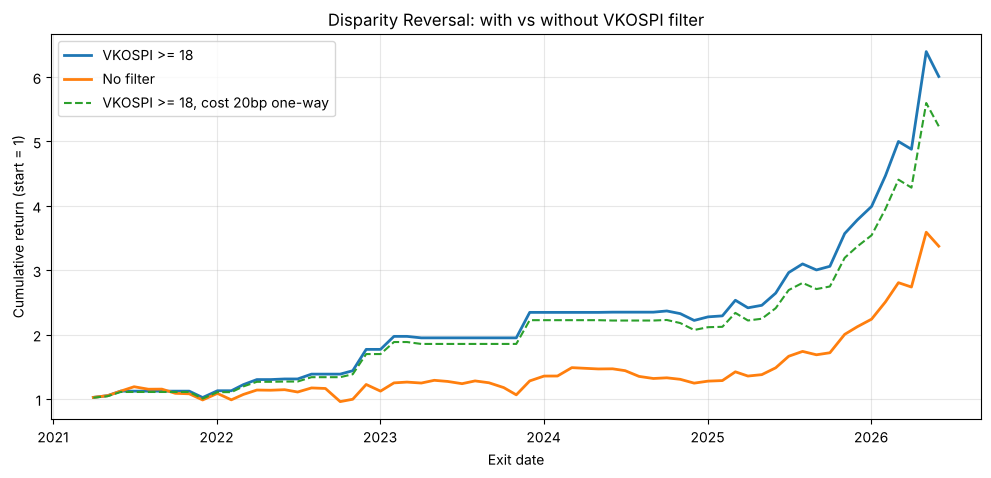

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(res_filter["exit_date"], res_filter["cum_ret"], label=f"VKOSPI >= {VKOSPI_THRESHOLD}", linewidth=2)
ax.plot(res_all["exit_date"], res_all["cum_ret"], label="No filter", linewidth=2)
ax.plot(res_filter_cost["exit_date"], res_filter_cost["cum_ret"],
        label=f"VKOSPI >= {VKOSPI_THRESHOLD}, cost {COST_BPS}bp one-way", linestyle="--")
ax.set_title("Disparity Reversal: with vs without VKOSPI filter")
ax.set_xlabel("Exit date")
ax.set_ylabel("Cumulative return (start = 1)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [12]:
# 어떤 종목이 뽑혔는지 확인
cols = ["date", "ticker", "name", "close", "ma20", "disparity_1m",
        "entry_date", "entry_open", "exit_date", "exit_open", "fwd_ret"]
hold_filter[cols].head(20)

,date,ticker,name,close,ma20,disparity_1m,entry_date,entry_open,exit_date,exit_open,fwd_ret
0,2021-02-26,326030,SK바이오팜,118000,145275.00,81.225262,2021-03-02,120500.0,2021-04-01,103500.0,-0.141079
1,2021-02-26,001440,대한전선,8475,10273.10,82.497007,2021-03-02,8584.0,2021-04-01,10228.0,0.191519
2,2021-02-26,011780,금호석유화학,211000,249100.00,84.704938,2021-03-02,217500.0,2021-04-01,265000.0,0.218391
3,2021-02-26,003090,대웅,36550,42702.50,85.592178,2021-03-02,36900.0,2021-04-01,32700.0,-0.113821
4,2021-02-26,009420,한올바이오파마,22050,25710.00,85.764294,2021-03-02,22200.0,2021-04-01,22950.0,0.033784
5,2021-02-26,000240,한국앤컴퍼니,17250,19972.50,86.368757,2021-03-02,17650.0,2021-04-01,18700.0,0.059490
6,2021-02-26,011210,현대위아,77100,88670.00,86.951618,2021-03-02,78900.0,2021-04-01,77800.0,-0.013942
7,2021-02-26,093370,후성,9864,11308.90,87.223337,2021-03-02,10108.0,2021-04-01,10303.0,0.019292
8,2021-02-26,034730,SK,262500,300400.00,87.383489,2021-03-02,270000.0,2021-04-01,285000.0,0.055556
9,2021-02-26,112610,씨에스윈드,72400,82464.90,87.794929,2021-03-02,73000.0,2021-04-01,76400.0,0.046575


## 5. 필터 효과는 어디서 오는가

필터 전략이 더 좋게 나왔다고 해서 "변동성이 높을 때 낙폭과대주가 잘 반등한다"가 증명된 건 아니다. 변동성이 튄 다음 달에는 시장 전체가 반등하는 경우가 많기 때문에, 아무 종목이나 들고 있었어도 좋았을 수 있다.

그래서 필터 없는 전략의 월별 수익률을 둘로 쪼갠다.

- **유니버스 수익률**: 같은 구간에 200종목을 동일가중으로 들고 있었을 때의 수익률. 시장 타이밍 몫이다.
- **초과수익률**: 전략 수익률 − 유니버스 수익률. 낙폭과대주를 골라서 생긴 몫이다.

이걸 신호일 VKOSPI가 18 이상이었던 달과 아니었던 달로 나눠서 비교한다.

In [13]:
# 월별 테이블: 필터 없는 전략, 유니버스 동일가중, 그 차이
monthly = res_all[["date", "entry_date", "exit_date", "vkospi", "strategy_ret"]].copy()
monthly = monthly.merge(
    rebal_df.groupby("date")["fwd_ret"].mean().rename("universe_ret"), on="date", how="left"
)
monthly["excess_ret"] = monthly["strategy_ret"] - monthly["universe_ret"]
monthly["high_vol"] = monthly["vkospi"] >= VKOSPI_THRESHOLD


def regime_table(monthly, cols, flag="high_vol"):
    # 고변동성/저변동성 달의 평균, t값, 승률과 두 집단 차이의 Welch t-test
    rows = []
    for col in cols:
        hi, lo = monthly.loc[monthly[flag], col], monthly.loc[~monthly[flag], col]
        test = stats.ttest_ind(hi, lo, equal_var=False)
        rows.append({
            "series": col,
            "high: months": len(hi),
            "high: mean": hi.mean(),
            "high: t": hi.mean() / (hi.std() / np.sqrt(len(hi))),
            "high: win": (hi > 0).mean(),
            "low: months": len(lo),
            "low: mean": lo.mean(),
            "low: t": lo.mean() / (lo.std() / np.sqrt(len(lo))),
            "low: win": (lo > 0).mean(),
            "diff": hi.mean() - lo.mean(),
            "diff p-value": test.pvalue,
        })
    return pd.DataFrame(rows).set_index("series")


regime_stats = regime_table(monthly, ["strategy_ret", "universe_ret", "excess_ret"])
regime_stats.round(4)

,high: months,high: mean,high: t,high: win,low: months,low: mean,low: t,low: win,diff,diff p-value
series,,,,,,,,,,
strategy_ret,36,0.0542,3.8776,0.7778,27,-0.0196,-1.8489,0.2963,0.0738,0.0001
universe_ret,36,0.0369,3.6388,0.7778,27,-0.0099,-1.2343,0.4815,0.0468,0.0006
excess_ret,36,0.0173,2.3572,0.5278,27,-0.0097,-1.6120,0.3704,0.0270,0.0061


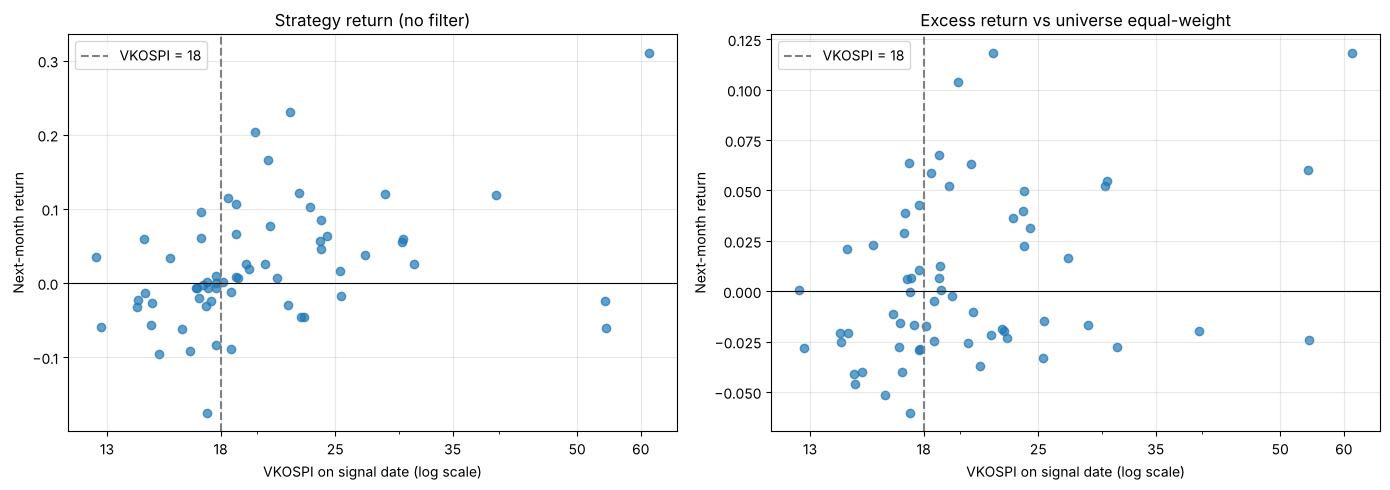

VKOSPI vs strategy_ret  Spearman rho = +0.43 (p = 0.000)
VKOSPI vs universe_ret  Spearman rho = +0.33 (p = 0.009)
VKOSPI vs excess_ret    Spearman rho = +0.31 (p = 0.013)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, col, title in [
    (axes[0], "strategy_ret", "Strategy return (no filter)"),
    (axes[1], "excess_ret", "Excess return vs universe equal-weight"),
]:
    ax.scatter(monthly["vkospi"], monthly[col], alpha=0.7)
    ax.axvline(VKOSPI_THRESHOLD, color="gray", linestyle="--", label=f"VKOSPI = {VKOSPI_THRESHOLD}")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xticks([13, 18, 25, 35, 50, 60])
    ax.set_xticklabels([13, 18, 25, 35, 50, 60])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("VKOSPI on signal date (log scale)")
    ax.set_ylabel("Next-month return")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

for col in ["strategy_ret", "universe_ret", "excess_ret"]:
    rho, p = stats.spearmanr(monthly["vkospi"], monthly[col])
    print(f"VKOSPI vs {col:13s} Spearman rho = {rho:+.2f} (p = {p:.3f})")

In [15]:
# 시장 노출을 감안한 뒤에도 남는 게 있는지: 전략 수익률을 유니버스 수익률에 회귀
def alpha_beta(y, x):
    reg = stats.linregress(x, y)
    resid = y - (reg.intercept + reg.slope * x)
    n = len(x)
    se_alpha = resid.std(ddof=2) * np.sqrt(1 / n + x.mean() ** 2 / ((x - x.mean()) ** 2).sum())
    return pd.Series({
        "months": n,
        "alpha (monthly)": reg.intercept,
        "alpha t": reg.intercept / se_alpha,
        "beta": reg.slope,
        "R2": reg.rvalue ** 2,
    })


pd.DataFrame({
    "All months": alpha_beta(monthly["strategy_ret"], monthly["universe_ret"]),
    f"VKOSPI >= {VKOSPI_THRESHOLD}": alpha_beta(
        monthly.loc[monthly["high_vol"], "strategy_ret"], monthly.loc[monthly["high_vol"], "universe_ret"]),
    f"VKOSPI < {VKOSPI_THRESHOLD}": alpha_beta(
        monthly.loc[~monthly["high_vol"], "strategy_ret"], monthly.loc[~monthly["high_vol"], "universe_ret"]),
}).round(4)

,All months,VKOSPI >= 18,VKOSPI < 18
months,63.0000,36.0000,27.0000
alpha (monthly),0.0018,0.0103,-0.0088
alpha t,0.3540,1.2262,-1.4021
beta,1.2302,1.1878,1.0926
R2,0.7720,0.7439,0.6820


**읽은 것**

- 전략 수익률은 VKOSPI 18 이상인 달 다음에 월평균 +5.4%, 미만인 달 다음에 −2.0%다. 차이는 뚜렷하다(p < 0.001).
- 그런데 유니버스 전체도 같은 구분에서 +3.7%와 −1.0%로 갈린다. 7.4%p 차이 가운데 4.7%p, 대략 3분의 2는 종목을 고르지 않아도 얻는 몫이다. 필터의 주된 역할은 **주식을 들고 있을 달을 고르는 것**이다.
- 나머지가 종목 선택 몫이다. 초과수익률은 고변동성 달에 월 +1.7%(t 2.4), 저변동성 달에 −1.0%(t −1.6)이고 둘의 차이는 유의하다(p 0.006). 방향은 보고서 주장과 같다. 변동성이 낮을 때 혼자 빠진 종목을 사면 유니버스보다 못하다.
- 다만 이 전략은 유니버스 대비 베타가 1.2 안팎이다. 베타를 감안한 알파는 고변동성 달에 월 +1.0%로 남지만 t값이 1.2라 유의하지 않다. 초과수익의 일부는 낙폭과대주가 단순히 더 많이 움직이는 종목이라서 생긴 것이다.

## 6. 이격도 5분위로 보면

하위 20개만 보면 팩터가 전체 종목에서 어떻게 작동하는지 알 수 없다. 매 신호일마다 이격도 순으로 5개 그룹(Q1 = 가장 많이 빠진 종목, Q5 = 가장 많이 오른 종목)을 만들어 다음 달 평균 수익률을 본다. 보고서 주장대로라면 고변동성 달에 Q1에서 Q5로 갈수록 수익률이 낮아져야 한다.

In [16]:
rebal_df["quintile"] = rebal_df.groupby("date")["disparity_1m"].transform(
    lambda x: pd.qcut(x.rank(method="first"), 5, labels=False)
) + 1

q_ret = rebal_df.groupby(["date", "quintile"])["fwd_ret"].mean().unstack()
q_ret.columns = [f"Q{int(c)}" for c in q_ret.columns]
q_ret["Q1-Q5"] = q_ret["Q1"] - q_ret["Q5"]
q_ret = q_ret.reset_index().merge(monthly[["date", "high_vol"]], on="date")

q_cols = ["Q1", "Q2", "Q3", "Q4", "Q5", "Q1-Q5"]
q_stats = regime_table(q_ret, q_cols)
q_stats[["high: mean", "high: t", "low: mean", "low: t", "diff p-value"]].round(4)

,high: mean,high: t,low: mean,low: t,diff p-value
series,,,,,
Q1,0.0474,3.8784,-0.0169,-1.9056,0.0001
Q2,0.0377,3.7297,-0.0118,-1.5141,0.0003
Q3,0.0331,3.3967,-0.0117,-1.3874,0.0009
Q4,0.0264,2.6879,-0.0034,-0.4544,0.0192
Q5,0.0400,2.8692,-0.0056,-0.4625,0.0165
Q1-Q5,0.0074,0.6425,-0.0112,-1.4258,0.1866


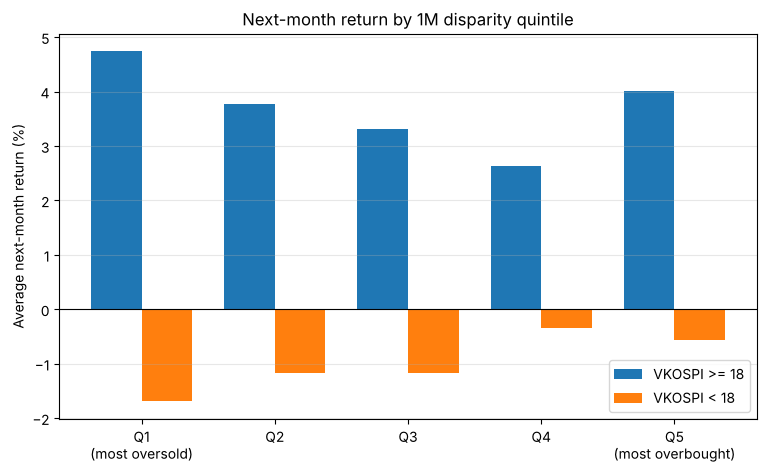

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(5)
w = 0.38
ax.bar(x - w / 2, q_stats.loc[["Q1", "Q2", "Q3", "Q4", "Q5"], "high: mean"] * 100, w,
       label=f"VKOSPI >= {VKOSPI_THRESHOLD}")
ax.bar(x + w / 2, q_stats.loc[["Q1", "Q2", "Q3", "Q4", "Q5"], "low: mean"] * 100, w,
       label=f"VKOSPI < {VKOSPI_THRESHOLD}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["Q1\n(most oversold)", "Q2", "Q3", "Q4", "Q5\n(most overbought)"])
ax.set_ylabel("Average next-month return (%)")
ax.set_title("Next-month return by 1M disparity quintile")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

**읽은 것**

- 고변동성 달에는 Q1(+4.7%)이 가장 높고 Q4(+2.6%)까지 내려간다. 여기까지는 주장과 맞다.
- 그런데 Q5, 즉 가장 많이 오른 종목도 +4.0%로 Q1 다음으로 높다. Q1−Q5 차이는 월 +0.7%(t 0.6)로 유의하지 않다. 양 끝이 모두 좋다는 건 낙폭과대라서가 아니라 변동이 큰 종목이라서 반등장에서 더 오른 것일 가능성을 시사한다.
- 저변동성 달에는 Q1이 −1.7%로 가장 나쁘다. 혼자 빠진 종목이 계속 빠지는 모습이고, 이쪽은 가설과 일치한다.

"고변동성 구간에서 낙폭과대주가 주도주보다 강하다"는 주장은 이 데이터에서는 방향만 맞고 통계적으로 확인되지는 않는다. 더 분명하게 나오는 건 "저변동성 구간에서는 낙폭과대주를 사지 말아야 한다" 쪽이다.

## 7. 임계값과 기간을 바꿔 보면

### 7-1. 임계값, 종목 수

18과 20종목은 보고서 기준을 그대로 가져온 값이다. 이 조합에서만 좋게 나오는 거라면 과최적화를 의심해야 한다.

In [18]:
rows = []
for th in [None, 15, 18, 20, 25, 30]:
    for n in [10, 20, 30]:
        res, _ = backtest_disparity(rebal_df, threshold=th, top_n=n)
        perf = calc_performance(res["strategy_ret"], res["invested"])
        rows.append({
            "threshold": "none" if th is None else th,
            "top_n": n,
            "CAGR": perf["CAGR"],
            "Sharpe": perf["Sharpe"],
            "MDD": perf["MDD"],
            "Invested Months": int(perf["Invested Months"]),
        })

sens = pd.DataFrame(rows)
order = ["none", 15, 18, 20, 25, 30]
display(sens.pivot(index="threshold", columns="top_n", values="Sharpe").loc[order].round(2).rename_axis(columns="Sharpe / top_n"))
display(sens.pivot(index="threshold", columns="top_n", values="CAGR").loc[order].round(3).rename_axis(columns="CAGR / top_n"))
display(sens[sens["top_n"] == TOP_N].set_index("threshold").loc[order, ["Invested Months", "MDD"]].round(3))

Sharpe / top_n,10,20,30
threshold,,,
none,0.93,0.93,1.04
15,1.06,1.06,1.14
18,1.68,1.71,1.75
20,1.40,1.40,1.43
25,0.84,0.73,0.74
30,0.72,0.57,0.53


CAGR / top_n,10,20,30
threshold,,,
none,0.301,0.261,0.265
15,0.330,0.291,0.282
18,0.446,0.407,0.381
20,0.324,0.301,0.277
25,0.152,0.117,0.107
30,0.123,0.086,0.072


,Invested Months,MDD
threshold,,
none,63,-0.194
15,55,-0.181
18,36,-0.088
20,25,-0.100
25,11,-0.060
30,7,-0.060


In [19]:
# 임계값을 하나 정하지 않고 VKOSPI 구간별로 그냥 나눠 본다
bins = [0, 15, 17, 18, 19, 21, 25, 100]
bucket = (
    monthly.groupby(pd.cut(monthly["vkospi"], bins), observed=True)
    .agg(months=("strategy_ret", "size"),
         strategy=("strategy_ret", "mean"),
         universe=("universe_ret", "mean"),
         excess=("excess_ret", "mean"))
)
bucket.round(4)

,months,strategy,universe,excess
vkospi,,,,
"(0, 15]",8,-0.0148,0.0052,-0.0200
"(15, 17]",7,-0.0355,-0.0121,-0.0234
"(17, 18]",12,-0.0136,-0.0187,0.0051
"(18, 19]",8,0.0254,0.0130,0.0124
"(19, 21]",6,0.0860,0.0559,0.0301
"(21, 25]",11,0.0536,0.0376,0.0160
"(25, 100]",11,0.0583,0.0433,0.0150


- 종목 수는 10, 20, 30 어느 쪽이든 결과가 비슷하다. 문제가 되지 않는다.
- 임계값은 18에서 Sharpe가 가장 높고(1.71) 15에서는 1.06, 20에서는 1.40, 25에서는 0.73이다. 18이 가장 좋은 값이라는 점은 걸린다. 15~20 범위에서는 모두 필터 없음(0.93)보다 높다. 25 이상에서는 진입이 11번 이하로 줄어 수익 낼 달까지 쉬게 되면서 필터 없음보다 낮아진다.
- 구간별 표가 더 믿을 만한 근거다. VKOSPI 18 이하 세 구간은 전략 수익률이 모두 마이너스이고 18을 넘는 네 구간은 모두 플러스다. 한두 달이 만든 결과가 아니라 수준에 따라 단계적으로 바뀐다. 신호일 VKOSPI의 중앙값이 18.8이라 18은 사실상 표본을 반으로 가르는 값이기도 하다.

### 7-2. 기간

2025년부터는 VKOSPI가 한 번도 18 아래로 내려가지 않았다. 이 구간에서는 필터가 항상 켜져 있어서 필터 전략과 필터 없는 전략이 같다. 필터가 실제로 달을 걸러낸 2021~2024년만 따로 본다.

In [20]:
def period_table(start, end):
    rf = res_filter[(res_filter["date"] >= start) & (res_filter["date"] <= end)]
    ra = res_all[(res_all["date"] >= start) & (res_all["date"] <= end)]
    mm = monthly[(monthly["date"] >= start) & (monthly["date"] <= end)]
    return pd.concat([
        calc_performance(rf["strategy_ret"], rf["invested"]).rename("VKOSPI Filter"),
        calc_performance(ra["strategy_ret"], ra["invested"]).rename("No Filter"),
        calc_performance(mm["universe_ret"]).rename("Universe EW"),
    ], axis=1)


print("2021-02 ~ 2024-12")
display(period_table("2021-01-01", "2024-12-31").round(3))
print("2025-01 ~ 2026-04")
display(period_table("2025-01-01", "2026-12-31").round(3))

print("2021~2024년만으로 본 구간 비교")
regime_table(monthly[monthly["date"] <= "2024-12-31"], ["strategy_ret", "universe_ret", "excess_ret"]).round(4)

2021-02 ~ 2024-12


,VKOSPI Filter,No Filter,Universe EW
Total Return,1.291,0.286,0.254
CAGR,0.236,0.066,0.060
Volatility,0.187,0.249,0.160
Sharpe,1.263,0.267,0.372
MDD,-0.088,-0.194,-0.232
Win Rate,0.340,0.511,0.617
Num Months,47.000,47.000,47.000
Invested Months,20.000,47.000,NaN
Win Rate (invested),0.800,0.511,NaN


2025-01 ~ 2026-04


,VKOSPI Filter,No Filter,Universe EW
Total Return,1.623,1.623,1.068
CAGR,1.061,1.061,0.724
Volatility,0.325,0.325,0.266
Sharpe,3.269,3.269,2.728
MDD,-0.060,-0.060,-0.084
Win Rate,0.750,0.750,0.750
Num Months,16.000,16.000,16.000
Invested Months,16.000,16.000,NaN
Win Rate (invested),0.750,0.750,NaN


2021~2024년만으로 본 구간 비교


,high: months,high: mean,high: t,high: win,low: months,low: mean,low: t,low: win,diff,diff p-value
series,,,,,,,,,,
strategy_ret,20,0.0449,2.6321,0.8,27,-0.0196,-1.8489,0.2963,0.0645,0.0029
universe_ret,20,0.0272,2.7441,0.8,27,-0.0099,-1.2343,0.4815,0.0371,0.0059
excess_ret,20,0.0177,1.8177,0.6,27,-0.0097,-1.6120,0.3704,0.0274,0.0225


- 2021~2024년(47개월, 진입 20번)만 봐도 필터 전략은 Sharpe 1.26, 필터 없는 전략은 0.27이다. 구간 비교도 같은 방향이다(전략 수익률 차이 p 0.003, 초과수익률 차이 p 0.02). 필터 효과가 2025년 이후 상승장에 기대고 있는 건 아니다.
- 반대로 누적수익률의 절대 크기는 2025년 이후에 크게 기대고 있다. 필터 전략의 누적 +501% 가운데 2024년 말까지가 +129%이고, 이후 16개월 동안 다시 2.6배가 됐다. 이 구간은 유니버스 동일가중도 2.1배가 된 장이다.

## 8. 벤치마크와 회전율

KOSPI200 지수를 전략과 **같은 구간**(매수일 시가 → 매도일 시가)으로 잘라서 비교한다. 지수 시작점을 2021년 1월 첫 거래일로 두면 전략 시작일과 어긋나기 때문에 구간을 맞췄다.

유니버스 동일가중이 지수보다 공정한 비교 대상이다. 같은 생존편향을 갖고 있기 때문이다.

In [21]:
ks200 = fdr.DataReader("KS200", START, END)
ks_open = ks200["Open"]

monthly["kospi200_ret"] = (
    monthly["exit_date"].map(ks_open).values / monthly["entry_date"].map(ks_open).values - 1
)

bm_compare = pd.concat([
    calc_performance(res_filter["strategy_ret"]).rename("VKOSPI Filter"),
    calc_performance(res_all["strategy_ret"]).rename("No Filter"),
    calc_performance(monthly["universe_ret"]).rename("Universe EW"),
    calc_performance(monthly["kospi200_ret"]).rename("KOSPI200"),
], axis=1)
bm_compare.round(3)

,VKOSPI Filter,No Filter,Universe EW,KOSPI200
Total Return,5.009,2.373,1.594,2.270
CAGR,0.407,0.261,0.199,0.253
Volatility,0.237,0.281,0.201,0.312
Sharpe,1.715,0.926,0.990,0.812
MDD,-0.088,-0.194,-0.232,-0.348
Win Rate,0.444,0.571,0.651,0.571
Num Months,63.000,63.000,63.000,63.000


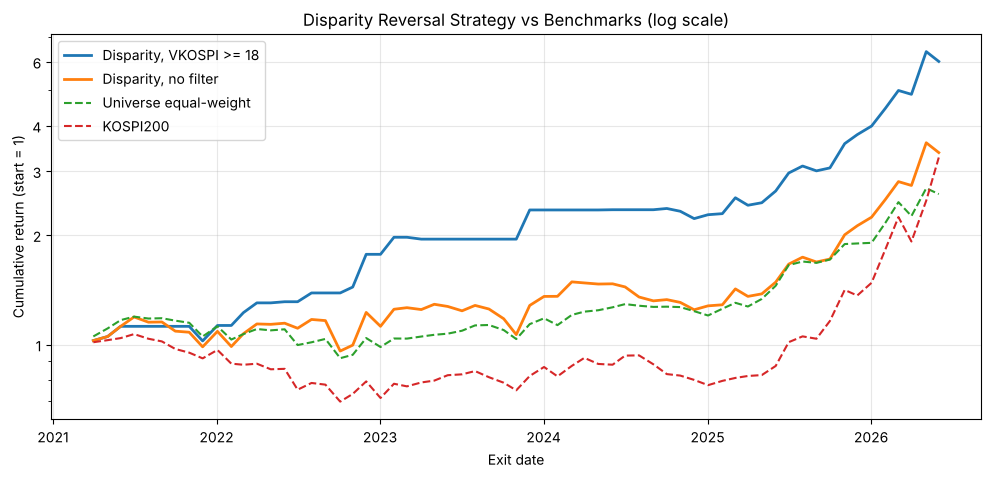

In [22]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(res_filter["exit_date"], res_filter["cum_ret"], label=f"Disparity, VKOSPI >= {VKOSPI_THRESHOLD}", linewidth=2)
ax.plot(res_all["exit_date"], res_all["cum_ret"], label="Disparity, no filter", linewidth=2)
ax.plot(monthly["exit_date"], (1 + monthly["universe_ret"]).cumprod(), label="Universe equal-weight", linestyle="--")
ax.plot(monthly["exit_date"], (1 + monthly["kospi200_ret"]).cumprod(), label="KOSPI200", linestyle="--")
ax.set_yscale("log")
ax.set_yticks([1, 2, 3, 4, 6])
ax.set_yticklabels([1, 2, 3, 4, 6])
ax.set_title("Disparity Reversal Strategy vs Benchmarks (log scale)")
ax.set_xlabel("Exit date")
ax.set_ylabel("Cumulative return (start = 1)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [23]:
# 회전율: 연달아 진입한 두 달 사이에 겹치는 종목 비율
picks = hold_filter.groupby("date")["ticker"].apply(set)
overlap = [
    len(picks.iloc[i] & picks.iloc[i - 1]) / TOP_N
    for i in range(1, len(picks))
    if next_rebal_map.get(picks.index[i - 1]) == picks.index[i]
]
print(f"연속 진입 {len(overlap)}번 평균: 전월 보유 종목의 {np.mean(overlap):.0%}가 다시 선정됨")

연속 진입 25번 평균: 전월 보유 종목의 12%가 다시 선정됨


- 필터 전략은 수익률, 변동성, 낙폭 모두 유니버스 동일가중과 KOSPI200보다 낫다. 낙폭이 작은 건 필터 없는 전략이 크게 잃은 달(2021-12, 2022-08, 2022-11, 2023-09 신호)이 모두 필터가 꺼진 달이었기 때문이다.
- 연달아 진입한 달 사이에 다시 뽑히는 종목은 평균 12% 수준이다. 매달 거의 전부를 갈아끼우는 전략이므로 4장에서 진입한 달마다 왕복 비용을 전부 뺀 가정이 과하지 않다. 편도 20bp를 넣으면 CAGR은 40.7%에서 37.1%로, Sharpe는 1.71에서 1.58로 내려간다.

## 9. 최근 신호일 기준 매수 후보

데이터의 마지막 날을 신호일로 보고, 그날 VKOSPI가 임계값 이상이면 이격도 하위 종목을 뽑는다. 백테스트와 같은 규칙이다.

In [24]:
signal_date = df["date"].max()
vk_on_signal = vk.loc[vk["date"] == signal_date, "vkospi"]

if vk_on_signal.empty:
    print(f"{signal_date.date()} VKOSPI 데이터 없음")
else:
    vkospi_now = vk_on_signal.iloc[0]
    print(f"{signal_date.date()} VKOSPI: {vkospi_now}")

    if vkospi_now >= VKOSPI_THRESHOLD:
        buy_list = (
            df[df["date"] == signal_date]
            .dropna(subset=["disparity_1m"])
            .sort_values("disparity_1m")
            .head(TOP_N)[["ticker", "name", "close", "ma20", "disparity_1m"]]
            .rename(columns={"ticker": "Ticker", "name": "Name", "close": "Close",
                             "ma20": "20DMA", "disparity_1m": "1M Disparity"})
            .reset_index(drop=True)
        )
        display(buy_list.round(2))
    else:
        print(f"VKOSPI {VKOSPI_THRESHOLD} 미만이라 진입하지 않음")

2026-06-30 VKOSPI: 93.8


,Ticker,Name,Close,20DMA,1M Disparity
0,307950,현대오토에버,530000,670200.0,79.08
1,272210,한화시스템,73000,89645.0,81.43
2,001430,세아베스틸지주,34800,42600.0,81.69
3,454910,두산로보틱스,90300,110475.0,81.74
4,010060,OCI홀딩스,214500,261550.0,82.01
5,022100,포스코DX,21650,26212.5,82.59
6,005380,현대차,495000,595425.0,83.13
7,064400,LG씨엔에스,78800,94130.0,83.71
8,267250,HD현대,199500,238085.0,83.79
9,011790,SKC,106600,127180.0,83.82


## 10. 정리

### 결과

2021-02 ~ 2026-04 신호일 63개월 기준이다.

| | VKOSPI ≥ 18 | 필터 없음 | 유니버스 동일가중 | KOSPI200 |
|---|---|---|---|---|
| 누적수익률 | +501% | +237% | +159% | +227% |
| CAGR | 40.7% | 26.1% | 19.9% | 25.3% |
| 연변동성 | 23.7% | 28.1% | 20.1% | 31.2% |
| Sharpe | 1.71 | 0.93 | 0.99 | 0.81 |
| MDD (월말 기준) | −8.8% | −19.4% | −23.2% | −34.8% |
| 진입한 달 | 36 | 63 | 63 | 63 |

처음 던진 세 질문에 대한 답은 이렇다.

1. **필터는 성과를 개선한다.** Sharpe가 0.93에서 1.71로 오르고 낙폭이 절반 아래로 줄어든다. 2021~2024년만 떼어 봐도, 편도 20bp 비용을 넣어도 유지된다.
2. **개선의 대부분은 시장 타이밍이다.** VKOSPI가 18 이상인 달 다음에는 유니버스 전체가 월 +3.7% 올랐고 미만인 달 다음에는 −1.0%였다. 낙폭과대주를 골라서 얻은 몫은 고변동성 달 기준 월 +1.7%(t 2.4)이고, 베타를 감안하면 유의성이 사라진다. 5분위로 보면 가장 많이 오른 종목도 같이 좋았다.
3. **임계값은 18 근처가 가장 좋지만 결과가 한 점에 기대고 있지는 않다.** VKOSPI 구간별로 나누면 18을 경계로 수익률 부호가 단계적으로 바뀐다.

정리하면 이 전략은 "변동성이 튄 뒤에 주식을 사고, 그때 낙폭과대주 쪽으로 기울인다"로 읽는 게 맞다. 보고서가 말한 낙폭과대 팩터 자체의 알파는 방향만 확인됐다. 오히려 분명한 건 반대편이다. 변동성이 낮은 구간에서 낙폭과대주를 사면 유니버스보다 못했다.

### 한계

1. **생존편향.** 가장 큰 문제다. 2026년 현재 KOSPI200에 들어 있는 종목으로 2021년부터 돌렸다. 낙폭과대주 전략에서 제일 아픈 경우는 빠진 종목이 계속 빠져서 지수에서 퇴출되는 건데, 그런 종목이 유니버스에 아예 없다. 지난 몇 년간 크게 올라 지수에 새로 들어온 종목은 오르기 전부터 유니버스에 포함돼 있다. 절대 수익률은 과대평가됐다고 봐야 한다. 유니버스 동일가중과 비교한 것도 그래서다.
2. **표본.** 월별 관측치가 63개, 진입은 36번이다. 2025년 이후는 유니버스 동일가중이 16개월 만에 두 배가 된 구간이라 다른 국면에서도 같은 결과가 나올지는 이 데이터로 알 수 없다.
3. **고정 임계값.** 2025년부터 VKOSPI 수준 자체가 올라가서 18이라는 값은 더 이상 아무것도 걸러내지 않는다. 최근 1~2년 분포 대비 백분위 같은 상대 기준이 필요하다.
4. **체결.** 시가 체결을 가정했다. 낙폭과대 종목은 시가 호가가 얇을 수 있다.
5. **배당 미반영, 현금 수익률 0.** 둘 다 전략에 불리한 방향이라 큰 문제는 아니다.
6. **Sharpe 계산.** 무위험수익률을 빼지 않았고 월 수익률로 연환산했다. MDD도 월말 기준이라 월중 낙폭은 빠져 있다.

### 다음에 해볼 것

- 과거 시점별 KOSPI200 구성종목으로 유니버스를 다시 만들어 생존편향 제거
- 기간을 2010년대까지 늘려서 여러 변동성 국면에서 확인
- VKOSPI 임계값을 이동 백분위로 바꾸기
- 종목 선택 효과만 보도록 지수선물 매도로 베타를 헤지한 버전
- 이격도에 종목별 변동성을 같이 넣어 "낙폭과대"와 "고변동성"을 분리
- 월말 고정이 아니라 VKOSPI가 급등한 날을 트리거로 쓰는 이벤트 방식

### 실행 방법

노트북과 같은 폴더에 아래 두 파일을 두고 위에서부터 실행한다.

- `vkospi.xlsx`: KRX 정보데이터시스템에서 받은 VKOSPI 일별 시세
- `kospi200_fdr_ohlcv.csv`: 없으면 1-1 셀이 FinanceDataReader로 받아서 만든다(4~5분)